# 01 — Adatbetöltés, tisztítás és feltáró adatelemzés (EDA)

**Szakdolgozat:** Sentiment Analysis of Customer Reviews using Machine Learning Techniques
**Témavezető:** Mutaz AlShafeey
**Adat:** a Booking.com adathalmaz `val.csv` fájlja (~200 000 review)

---

## Mit csinálunk ebben a notebookban?

| # | Lépés | Dolgozat-fejezet |
|---|---|---|
| 1 | Környezet és importok | — |
| 2 | Adat betöltése + **a névütközés tisztázása** | 4. Data Sources |
| 3 | Adatminőség: hiányzó értékek, duplikátumok, hosszak | 6.1 Preprocessing |
| 4 | Sentiment-címkék + **küszöb-érzékenységi vizsgálat** | 6.1 Preprocessing |
| 5 | Szűrés és tisztítás | 6.1 Preprocessing |
| 6 | Alapvető EDA-ábrák | 9. EDA |
| 7 | **Leíró statisztikák és kereszttáblák** | 9. EDA |
| 8 | Aspektus-előzetes | 7. ABSA / 9. EDA |
| 9 | 60/20/20 felosztás és mentés | 8. Data Split |

> **Minden ábra és táblázat automatikusan mentődik** a `results/` mappába.
> Amikor a dolgozatot írod, onnan másolsz — nem futtatod újra ezt a notebookot.

## 1. Környezet és importok

In [1]:
# A notebooks/ mappából futunk, ezért a szülőmappát hozzá kell adni az
# elérési úthoz, hogy a `src` csomagot importálni tudjuk.
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import descriptives as ds
from src import aspects as asp
from src import text_analysis as ta
from src import evaluation as ev

# Reprodukálhatóság: EZ A LEGFONTOSABB SOR a notebookban.
# Enélkül minden futtatás kicsit más eredményt ad.
set_seed()
PATHS.ensure()

# Egységes ábrastílus az egész dolgozathoz (színek, betűméret, 300 DPI mentés)
apply_plot_style()

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

print(f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"Seed: {CFG.random_seed}")
print(f"Adatfájl: data/raw/{CFG.local_csv_name}")

pandas 3.0.6 | numpy 2.5.3
Seed: 42
Adatfájl: data/raw/val.csv


## 2. Adat betöltése

### ⚠ Fontos névtisztázás — ezt a dolgozatban is le kell írni

A fájl neve `val.csv`, mert ez a **Booking.com saját** train/validation/test
felosztásának validációs része. **Nálunk viszont ez a teljes munkaadathalmaz**,
amit MI osztunk fel 60/20/20 arányban saját tanító/validációs/teszt halmazra.

```
Booking.com felosztása:     train.csv    val.csv ←EZT HASZNÁLJUK    test.csv
                                            │
                            ┌───────────────┴───────────────┐
A MI felosztásunk:       train (60%)   validation (20%)   test (20%)
```

A két "validation" szónak **semmi köze egymáshoz**. A kódban ezért hívjuk a
betöltött adathalmazt `booking_val_split`-nek, nem `validation`-nek.

**Amit a dolgozat 4. fejezetébe írj:** „A kísérletekhez a Booking.com
adathalmaz publikált validációs részhalmazát használtam (kb. 200 000 review).
Ez a teljes adathalmaz véletlenszerű részhalmaza, így reprezentatívnak
tekinthető; a számításigény csökkentése érdekében esett rá a választás."

> Ez egy teljesen legitim döntés — 200 ezer review bőven elegendő ehhez a
> feladathoz. De **indokolni kell**, különben a bíráló megkérdezi, miért nem a
> teljes adatot használtad.

In [2]:
# A loader felismeri az oszlopneveket, és kiírja, mit talált.
# Ha valamelyik oszlop hiányzik, figyelmeztet — nézd meg a kimenetet!
df_raw = dl.load_dataset_by_name("booking_local")

print(f"\nBetöltve: {len(df_raw):,} sor, {df_raw.shape[1]} oszlop")
print(f"Oszlopok: {list(df_raw.columns)}")

11:41:16 | INFO    | src.data_loading | Gyorsítótárból töltök: booking_local_val__v2.parquet



Betöltve: 203,787 sor, 20 oszlop
Oszlopok: ['review_id', 'text', 'score', 'score_scale_max', 'dataset', 'review_positive', 'review_negative', 'guest_type', 'guest_country', 'room_nights', 'month', 'accommodation_id', 'accommodation_type', 'accommodation_score', 'accommodation_country', 'accommodation_star_rating', 'location_is_beach', 'location_is_ski', 'location_is_city_center', 'review_helpful_votes']


In [3]:
# Nézz meg néhány valódi sort — MINDIG, minden adathalmaznál.
# Sok hibát csak így veszel észre (helykitöltő szövegek, kódolási hibák).
df_raw.head(3)

,review_id,text,score,score_scale_max,dataset,review_positive,review_negative,guest_type,guest_country,room_nights,month,accommodation_id,accommodation_type,accommodation_score,accommodation_country,accommodation_star_rating,location_is_beach,location_is_ski,location_is_city_center,review_helpful_votes
0,booking_val_split_0,"Hope is relatively close to where I live, so this might just become a ""hop on the bike and cruise there for a weeke....",9.0,10.0,booking_val_split,"This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movi...",,Group,Jof,2,8,-225497943,Motel,7.7,Canada,3.0,0,0,0,0
1,booking_val_split_1,Close to the station and within walking distance of the centre,8.0,10.0,booking_val_split,Close to the station and within walking distance of the centre,,Solo traveller,Mejok,1,7,2110216461,Hotel,7.7,Netherlands,3.0,0,0,1,0
2,booking_val_split_2,"Excellent service. Excellent customer service, great location and the view, good breakfast spread, easy access to ci...",8.0,10.0,booking_val_split,"Excellent customer service, great location and the view, good breakfast spread, easy access to city centre, clean fa...",Kept on waking up in the middle of the night to a noisy boiler or something.,Family with children,Mejok,3,3,-1626991710,Hotel,7.9,United Kingdom,3.0,0,0,0,0


> **Ha a fenti cella hibát dobott** („Nem találom a pontszám oszlopot"), akkor a
> CSV oszlopnevei eltérnek a várttól. A hibaüzenet kiírja a tényleges neveket —
> küldd át, és kiegészítem a `_BOOKING_ALIASES` szótárat a `data_loading.py`-ban.

## 3. Adatminőség

In [4]:
print("=== Típusok ===")
print(df_raw.dtypes.to_string())

print("\n=== Hiányzó értékek ===")
miss = ds.missing_report(df_raw)
print(miss.to_string() if len(miss) else "Nincs hiányzó érték.")

print("\n=== Duplikátumok (szöveg alapján) ===")
n_dup = df_raw["text"].duplicated().sum()
print(f"{n_dup:,} db ({n_dup/len(df_raw):.2%})")

print("\n=== Pontszám ===")
print(df_raw["score"].describe().to_string())

=== Típusok ===
review_id                        str
text                          string
score                        float64
score_scale_max              float64
dataset                          str
review_positive                  str
review_negative                  str
guest_type                       str
guest_country                    str
room_nights                    int64
month                          int64
accommodation_id               int64
accommodation_type               str
accommodation_score          float64
accommodation_country            str
accommodation_star_rating    float64
location_is_beach              int64
location_is_ski                int64
location_is_city_center        int64
review_helpful_votes           int64

=== Hiányzó értékek ===
               hiányzó   arány
guest_country      228  0.0011

=== Duplikátumok (szöveg alapján) ===
409 db (0.20%)

=== Pontszám ===
count    203787.000000
mean          8.870705
std           1.154789
min           3.

In [5]:
# Szöveghossz — ez dönti el, mekkora max_length kell majd a BERT-nek.
df_raw["n_chars"] = df_raw["text"].str.len()
df_raw["n_words"] = df_raw["text"].str.split().str.len()

print(df_raw[["n_chars", "n_words"]].describe(
    percentiles=[.5, .75, .9, .95, .99]).round(1).to_string())

q95 = df_raw["n_words"].quantile(0.95)
print(f"\nA reviewk 95%-a rövidebb, mint {q95:.0f} szó.")
print(f"A CFG.max_length = {CFG.max_length} token ebből kb. "
      f"{'ELÉG' if CFG.max_length > q95 * 1.3 else 'KEVÉS LEHET — fontold meg a 256-ot'}.")
print("(Ökölszabály: 1 szó ≈ 1,3 token angolban.)")

        n_chars   n_words
count  203787.0  203787.0
mean      278.4      49.1
std       237.5      43.7
min         0.0       0.0
50%       214.0      37.0
75%       354.0      63.0
90%       550.0      99.0
95%       716.0     130.0
99%      1184.0     215.0
max      3922.0     733.0

A reviewk 95%-a rövidebb, mint 130 szó.
A CFG.max_length = 256 token ebből kb. ELÉG.
(Ökölszabály: 1 szó ≈ 1,3 token angolban.)


In [6]:
# Konkrét példák három pontszám-tartományból.
# Figyeld meg, mennyire NEM különül el nyelvileg a középső sáv!
for lo, hi, cim in [(1, 5.9, "ALACSONY"), (6.0, 7.9, "KÖZEPES"), (8.0, 10, "MAGAS")]:
    sub = df_raw[(df_raw["score"] >= lo) & (df_raw["score"] <= hi)]
    print(f"\n{'='*70}\n{cim} pontszám ({lo}–{hi}) — {len(sub):,} review\n{'='*70}")
    for _, r in sub.sample(min(2, len(sub)), random_state=CFG.random_seed).iterrows():
        print(f"[{r['score']}] {r['text'][:220]}")


ALACSONY pontszám (1–5.9) — 1,407 review
[5.0] Poor service. View, historical meaning, lovely breakfast. A beautiful hotel with such a history but sadly very neglected. Corridors awful, dirty carpets. In the room empty toiletres. Receptionist also did not pay attenti
[5.0] Transit Motel close to airport. Close to the airport within walking distance of domestic terminal, but wouldn't suggest walking. Basic but adequate for an overnight stay. Food cooked on site was very good. In a sleazy ne

KÖZEPES pontszám (6.0–7.9) — 25,246 review
[7.0] Adequate for our needs. Location, free parking, very walkable, close to amenities No lifts to higher floors, only stairs. Will struggle if you have multiple luggages. We took an overnight bag and left the big luggage in 
[7.0] Great rooftop with pool, the room was comfortable and a good size. This hostel is so sleek, and seems to have a few activities going on. It has a co-working space which looks quite nice too. As mentioned by others, the b

MAGAS

## 4. Sentiment-címkék képzése

**Ez a dolgozat egyik legfontosabb módszertani döntése.**

Az adatban nincs kész `positive / neutral / negative` címke, csak egy 1–10-es
vendégpontszám. Ebből képezzük a három osztályt:

| Feltétel | Címke |
|---|---|
| `score ≤ 6` | negative |
| `6 < score < 8` | neutral |
| `score ≥ 8` | positive |

A 6/8 vágás a szakirodalomban gyakori, de **önkényes**. Ezért futtatunk alább egy
**érzékenységi vizsgálatot**: megnézzük, mennyire változik az osztályeloszlás más
küszöbökkel. Ez pont az a módszertani alaposság, amit a bírálók keresnek.

In [7]:
df = pp.add_sentiment_labels(df_raw)

dist = df["sentiment"].value_counts().reindex(list(CFG.labels))
summary = pd.DataFrame({"db": dist, "arány": (dist / len(df)).round(4)})
display(summary)

imbalance = dist.max() / dist.min()
print(f"Kiegyensúlyozatlansági arány: {imbalance:.1f}x")
print("=> Ezért lesz a MACRO-F1 a fő metrikánk (nem az accuracy),")
print("   és ezért használunk class_weight='balanced'-et a modelleknél.")

,db,arány
sentiment,,
negative,26647,0.1308
neutral,45736,0.2244
positive,131404,0.6448


Kiegyensúlyozatlansági arány: 4.9x
=> Ezért lesz a MACRO-F1 a fő metrikánk (nem az accuracy),
   és ezért használunk class_weight='balanced'-et a modelleknél.


A pontszám különböző értékei és gyakoriságuk:
              db   arány
score                   
3.000000      32  0.0002
4.000000     129  0.0006
5.000000    1246  0.0061
6.000000    4742  0.0233
6.666675       1  0.0000
7.000000   20497  0.1006
7.083325       5  0.0000
7.500000       1  0.0000
7.916675       3  0.0000
8.000000   45723  0.2244
8.333325       2  0.0000
8.750000       2  0.0000
9.000000   50961  0.2501
9.166675       5  0.0000
9.583325      12  0.0001
10.000000  80426  0.3947

Átlag: 8.87 | Medián: 9.0
  P05: 7.0
  P10: 7.0
  P25: 8.0
  P50: 9.0
  P75: 10.0


11:41:52 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_score_distribution.png


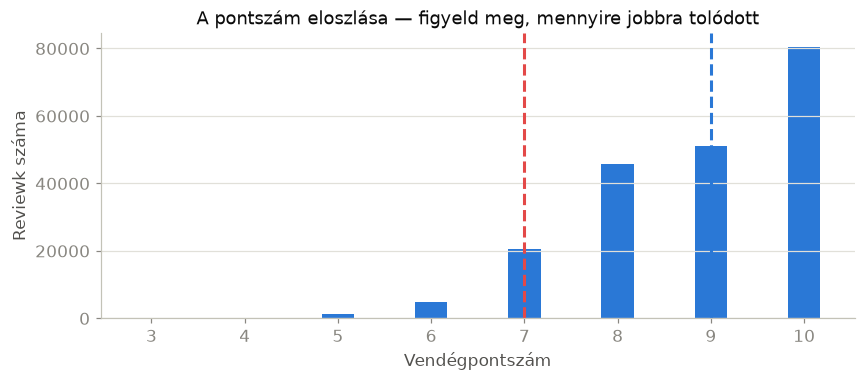

In [8]:
# ELŐSZÖR nézzük meg, hogyan oszlik el a pontszám. Ez dönti el, hogy a
# 6/8 küszöb egyáltalán működőképes-e ezen az adaton.
vc = df_raw["score"].value_counts().sort_index()
print("A pontszám különböző értékei és gyakoriságuk:")
print(pd.DataFrame({"db": vc, "arány": (vc / len(df_raw)).round(4)}).to_string())

print(f"\nÁtlag: {df_raw['score'].mean():.2f} | Medián: {df_raw['score'].median():.1f}")
for q in [0.05, 0.10, 0.25, 0.50, 0.75]:
    print(f"  P{int(q*100):02d}: {df_raw['score'].quantile(q):.1f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(vc.index, vc.values, width=0.35, color="#2a78d6")
ax.axvline(CFG.neg_threshold, color=SENTIMENT_COLORS["negative"], ls="--", lw=2)
ax.axvline(CFG.pos_threshold, color=SENTIMENT_COLORS["positive"], ls="--", lw=2)
ax.set(xlabel="Vendégpontszám", ylabel="Reviewk száma",
       title="A pontszám eloszlása — figyeld meg, mennyire jobbra tolódott")
ax.grid(axis="x", visible=False)
plt.tight_layout()
ev.save_figure("01_score_distribution")
plt.show()

In [9]:
# CÍMKÉZÉSI SZABÁLYOK ÖSSZEHASONLÍTÁSA
#
# Ez a táblázat a dolgozat 6.1 fejezetének egyik kulcsábrája. Megmutatja,
# hogy a küszöbválasztás nem technikai mellékesség, hanem érdemben
# meghatározza a feladat nehézségét.
#
# Kétféle logika szerepel benne:
#   FIX küszöb        -> ABSZOLÚT elégedettség ("6 alatt = rossz élmény")
#   KVANTILIS küszöb  -> RELATÍV elégedettség ("az alsó negyed")
# Mindkettő védhető, de NEM ugyanazt állítja — a dolgozatban le kell írni,
# melyiket választottad és miért.
comp = pp.label_distribution_report(df_raw["score"], df_raw["score_scale_max"])
display(comp)
ev.save_table(comp, "01_label_scheme_comparison")

print("\nMire figyelj:")
print("  • 'legkisebb osztály (db)': a BERT finomhangolásához osztályonként")
print("    legalább néhány ezer példa kell. Pár száz kevés.")
print("  • 'kiegyensúlyozatlanság': a legnagyobb és legkisebb osztály aránya.")
print("    10x felett a modell hajlamos egyszerűen a többséget tippelni.")
print("\n=> Válaszd ki a sort, ami mellett érvelni tudsz, és írd be a")
print("   config.py-ba a neg_threshold / pos_threshold értékeket.")

11:42:03 | INFO    | src.preprocessing | A pontszám diszkrét: 16 különböző érték, ebből 8 egész szám. Csak az egész számok határán futó küszöbök adnak eltérő felosztást.


,küszöbök,neg pontok,neu pontok,pos pontok,negative,neutral,positive,legkisebb osztály (db),kiegyensúlyozatlanság
szabály,,,,,,,,,
A) 6 / 8 — szigorú,6 / 8,3–6,7,8–10,0.0302,0.1006,0.8692,6149,28.8
B) 7 / 9 — kiegyensúlyozott,7 / 9,3–7,8,9–10,0.1308,0.2244,0.6448,26647,4.9
C) 7 / 10 — széles közép,7 / 10,3–7,8–9,10,0.1308,0.4746,0.3947,26647,3.6
D) 8 / 10 — relatív,8 / 10,3–8,9,10,0.3552,0.2502,0.3947,50982,1.6


11:42:03 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_label_scheme_comparison.csv



Mire figyelj:
  • 'legkisebb osztály (db)': a BERT finomhangolásához osztályonként
    legalább néhány ezer példa kell. Pár száz kevés.
  • 'kiegyensúlyozatlanság': a legnagyobb és legkisebb osztály aránya.
    10x felett a modell hajlamos egyszerűen a többséget tippelni.

=> Válaszd ki a sort, ami mellett érvelni tudsz, és írd be a
   config.py-ba a neg_threshold / pos_threshold értékeket.


## 5. Szűrés és tisztítás

In [10]:
# A build_dataset() elvégzi: szűrés -> címkézés -> kétféle tisztítás.
#
# A kétféle tisztítás SZÁNDÉKOS:
#   text_clean  -> TF-IDF-hez: agresszív (kisbetű, írásjelek ki, stopword ki,
#                  lemmatizálás). A zsák-a-szavak modellnek segít a zajszűrés.
#   text_bert   -> BERT-hez: minimális. A transformer a kontextusból tanul;
#                  ha kidobnád a tagadást, a "not clean" -> "clean" lenne,
#                  vagyis az ELLENKEZŐJÉT tanítanád neki.
#
# 200k soron ez néhány percig fut (a lemmatizálás a lassú rész).
df = pp.build_dataset(df_raw, classic_clean=True, minimal_clean=True, balance="none")

df["n_words"] = df["text"].str.split().str.len()
df["n_chars"] = df["text"].str.len()

print(f"\nVégleges méret: {len(df):,} sor")
print(df["sentiment"].value_counts().to_string())

11:42:15 | INFO    | src.preprocessing | --- Szűrési napló ---
11:42:15 | INFO    | src.preprocessing | kiindulás                                       203787  (+0)
11:42:15 | INFO    | src.preprocessing | rövid szövegek (<10 kar.) eltávolítva           203662  (-125)
11:42:15 | INFO    | src.preprocessing | extrém hosszúak (>5000 kar.) eltávolítva        203662  (+0)
11:42:15 | INFO    | src.preprocessing | duplikátumok eltávolítva                        203340  (-322)
11:42:15 | INFO    | src.preprocessing | nem angol szövegek eltávolítva                  203328  (-12)
11:42:19 | INFO    | src.preprocessing | Klasszikus tisztítás futtatása 203328 soron (eltarthat egy ideig)...



Végleges méret: 203,328 sor
sentiment
positive    131103
neutral      45614
negative     26611


In [11]:
# Mit CSINÁLT a tisztítás? Ezt a példát tedd be a dolgozat 6.1 fejezetébe!
ex = df.iloc[0]
print("EREDETI:\n ", ex["text"][:280])
print("\nBERT-hez (minimális tisztítás):\n ", ex["text_bert"][:280])
print("\nTF-IDF-hez (teljes tisztítás):\n ", ex["text_clean"][:280])

EREDETI:
  Hope is relatively close to where I live, so this might just become a "hop on the bike and cruise there for a weeke. This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movie theatre just around the corner and as well a 

BERT-hez (minimális tisztítás):
  Hope is relatively close to where I live, so this might just become a "hop on the bike and cruise there for a weeke. This motel is in the Center of Hope. You can get groceries, restaurants, pubs on food in just short distance, a movie theatre just around the corner and as well a 

TF-IDF-hez (teljes tisztítás):
  hope relatively close live might become hop bike cruise weeke motel center hope get grocery restaurant pub food short distance movie theatre around corner well small nice park next building look like could use bit love outside room extraordinarily clean especially motel absolutel


In [12]:
# CSONKOLÁSI ELLENŐRZÉS — a BERT max_length beállításához
#
# A szöveg felépítése:  cím . pozitív_rész   negatív_rész
# A tokenizáló a VÉGÉT vágja le, tehát elsőként a NEGATÍV tartalmat.
# Ha ez sok reviewt érint, a modell szisztematikusan kevesebb negatív jelet
# lát — ami a pozitív osztály felé torzítana.
for L in [128, 192, 256, 384]:
    rep = pp.truncation_report(df, max_length=L, text_col="text_bert")
    tr = rep.loc["csonkolva"]
    print(f"max_length={L:3d}  ->  csonkolva: {tr['arány']:6.2%} ({int(tr['db']):,} review)")

print(f"\nA jelenlegi beállítás: CFG.max_length = {CFG.max_length}")
print("\nRészletes bontás a jelenlegi értékkel:")
display(pp.truncation_report(df, max_length=CFG.max_length, text_col="text_bert"))
print("Ha a 'csonkolva' sorban az osztályarányok ELTÉRNEK az 'elfér' sorétól,")
print("a csonkolás torzít -> növeld a max_length-et.")

max_length=128  ->  csonkolva: 10.67% (21,694 review)
max_length=192  ->  csonkolva:  3.60% (7,322 review)
max_length=256  ->  csonkolva:  1.40% (2,846 review)
max_length=384  ->  csonkolva:  0.31% (640 review)

A jelenlegi beállítás: CFG.max_length = 256

Részletes bontás a jelenlegi értékkel:


,arány,db,positive,neutral,negative
elfér,0.986,200482,0.6464,0.2241,0.1295
csonkolva,0.014,2846,0.5309,0.2400,0.2291


Ha a 'csonkolva' sorban az osztályarányok ELTÉRNEK az 'elfér' sorétól,
a csonkolás torzít -> növeld a max_length-et.


## 6. Alapvető EDA-ábrák

11:43:19 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_eda_overview.png


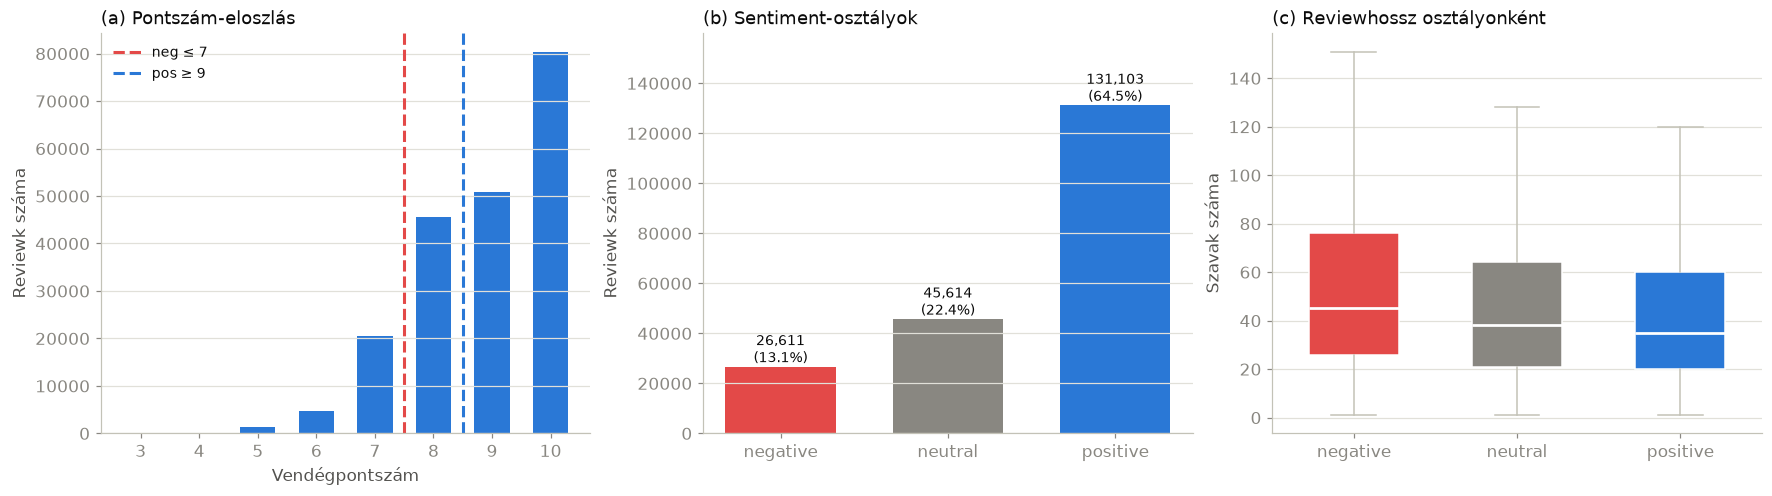

In [13]:
order = list(CFG.labels)
# Külön ábrákba, nem egy háromosztatúba: a három panel más-más y-tengelyt
# használ, és egymás mellé zsúfolva a tengelyfeliratok egymásra csúsznak.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)

# ---- (a) Pontszám-eloszlás a küszöbökkel ----
# A pontszám DISZKRÉT (egész értékek), ezért oszlopdiagram, nem hisztogram.
# A hisztogram tetszőleges binhatárokat húzna a diszkrét értékek közé.
vc = df["score"].round().value_counts().sort_index()
axes[0].bar(vc.index, vc.values, width=0.6, color="#2a78d6")
axes[0].axvline(CFG.neg_threshold + 0.5, color=SENTIMENT_COLORS["negative"],
                ls="--", lw=2, label=f"neg ≤ {CFG.neg_threshold:g}")
axes[0].axvline(CFG.pos_threshold - 0.5, color=SENTIMENT_COLORS["positive"],
                ls="--", lw=2, label=f"pos ≥ {CFG.pos_threshold:g}")
axes[0].set(xlabel="Vendégpontszám", ylabel="Reviewk száma")
axes[0].set_title("(a) Pontszám-eloszlás", loc="left")
axes[0].legend(fontsize=9)
axes[0].grid(axis="x", visible=False)

# ---- (b) Osztályeloszlás ----
counts = df["sentiment"].value_counts().reindex(order)
axes[1].bar(order, counts.values, color=[SENTIMENT_COLORS[l] for l in order], width=0.66)
for i, v in enumerate(counts.values):
    axes[1].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
axes[1].set(ylabel="Reviewk száma")
axes[1].set_title("(b) Sentiment-osztályok", loc="left")
axes[1].margins(y=0.22)
axes[1].grid(axis="x", visible=False)

# ---- (c) Szöveghossz osztályonként ----
# FIGYELEM: a matplotlib 3.9-től a boxplot `labels` paramétere `tick_labels`.
# Hogy verziófüggetlen legyen, egyiket sem adjuk át — külön állítjuk a ticket.
data = [df.loc[df["sentiment"].astype(str) == l, "n_words"].values for l in order]
bp = axes[2].boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                     medianprops=dict(color="white", linewidth=1.8))
for patch, l in zip(bp["boxes"], order):
    patch.set_facecolor(SENTIMENT_COLORS[l])
    patch.set_edgecolor(INK["surface"])
for part in ("whiskers", "caps"):
    for art in bp[part]:
        art.set_color(INK["axis"])
axes[2].set_xticks(range(1, len(order) + 1), order)
axes[2].set(ylabel="Szavak száma")
axes[2].set_title("(c) Reviewhossz osztályonként", loc="left")
axes[2].grid(axis="x", visible=False)

ev.save_figure("01_eda_overview")
plt.show()

In [14]:
# Számszerűsítsd, amit a (c) ábrán látsz — ez megy a szövegbe.
lens = df.groupby("sentiment", observed=True)["n_words"].agg(["count", "mean", "median"]).round(1)
display(lens)

neg_m = lens.loc["negative", "median"]; pos_m = lens.loc["positive", "median"]
print(f"A negatív reviewk mediánhossza {neg_m:.0f} szó, a pozitívaké {pos_m:.0f}.")
print("\nTipikus megfigyelés: a NEGATÍV reviewk hosszabbak — az elégedetlen vendég")
print("részletesen leírja a problémát, míg a pozitív értékelés gyakran pár szó.")
print("Ez önmagában is prediktív jel, és a hibaelemzésnél vissza fog térni.")

,count,mean,median
sentiment,,,
negative,26611,59.4,45.0
neutral,45614,50.2,38.0
positive,131103,46.8,35.0


A negatív reviewk mediánhossza 45 szó, a pozitívaké 35.

Tipikus megfigyelés: a NEGATÍV reviewk hosszabbak — az elégedetlen vendég
részletesen leírja a problémát, míg a pozitív értékelés gyakran pár szó.
Ez önmagában is prediktív jel, és a hibaelemzésnél vissza fog térni.


### Melyik szavak jellemzőek egy-egy osztályra?

Kézenfekvő lenne osztályonként a **leggyakoribb** szavakat kilistázni. Ez
azonban használhatatlan eredményt ad: mindhárom osztályban ugyanazok a szavak
vezetnének (*room, location, staff, good*), mert a gyakori szavak mindenhol
gyakoriak.

A jó kérdés nem az, hogy *mely szavak gyakoriak a negatív reviewkban*, hanem
hogy **mely szavak gyakoribbak a negatívban, mint a többiben**. Erre a
**súlyozott log-odds arányt** használjuk (Monroe, Colaresi & Quinn, 2008):

1. **log-odds**: hányszor valószínűbb a kifejezés ebben az osztályban, mint a
   többiben — logaritmizálva, hogy szimmetrikus legyen.
2. **z-értékké normálás**: a ritka kifejezések aránya véletlenül is kiugorhat,
   ezért a becslés szórásával osztunk. Így a lista tetejére olyan kifejezések
   kerülnek, amelyek **gyakoriak ÉS megkülönböztetőek**.

A hivatkozást tedd be az irodalomjegyzékbe — ez egy bevett, citálható módszer,
nem házi megoldás.

11:43:45 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_top_words_by_sentiment.png


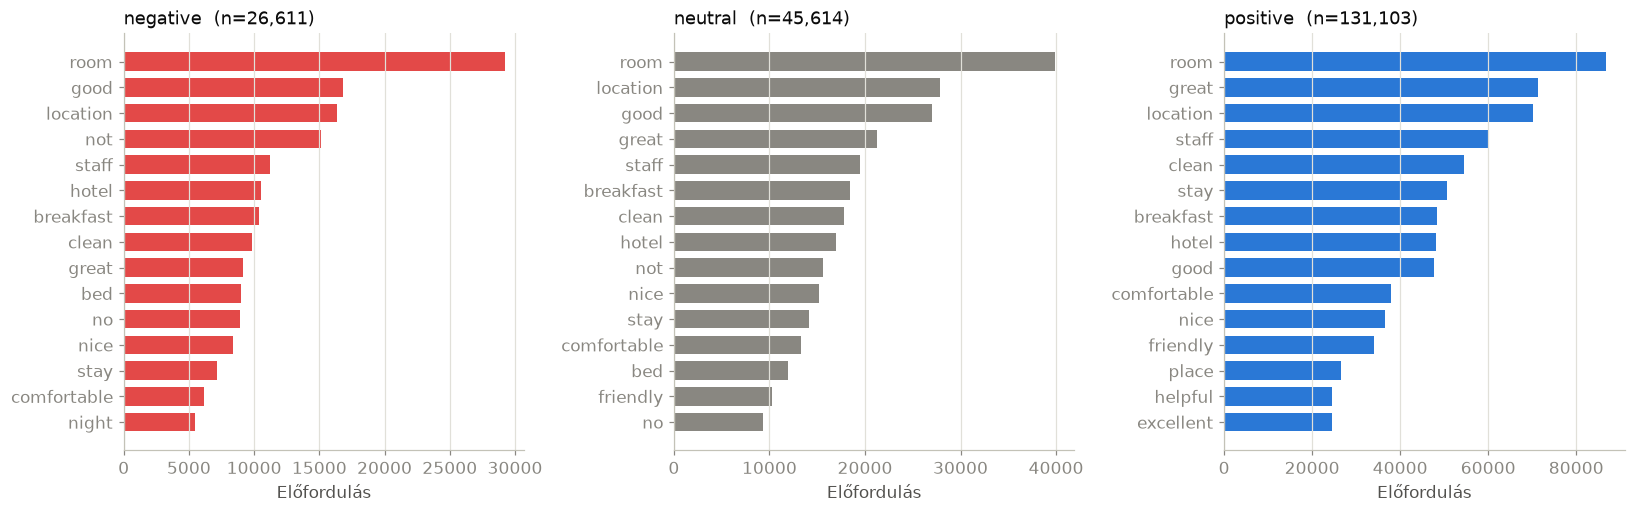

In [15]:
# Leggyakoribb kifejezések osztályonként — az első betekintés abba,
# MI hajtja a sentimentet.
from sklearn.feature_extraction.text import CountVectorizer

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, label in zip(axes, CFG.labels):
    texts = df.loc[df["sentiment"].astype(str) == label, "text_clean"]
    if len(texts) == 0:
        continue
    cv = CountVectorizer(max_features=15, ngram_range=(1, 2), min_df=3)
    X = cv.fit_transform(texts)
    freq = pd.Series(np.asarray(X.sum(axis=0)).ravel(),
                     index=cv.get_feature_names_out()).sort_values()
    ax.barh(freq.index, freq.values, color=SENTIMENT_COLORS[label], height=0.72)
    ax.set_title(f"{label}  (n={len(texts):,})", loc="left")
    ax.set_xlabel("Előfordulás")
    ax.grid(axis="y", visible=False)

plt.tight_layout()
ev.save_figure("01_top_words_by_sentiment")
plt.show()

11:44:08 | INFO    | src.text_analysis | Szókincs: 15619 kifejezés (1-2-gram), összesen 7647315 token
11:44:08 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_distinctive_terms.csv
11:44:09 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_distinctive_terms.png


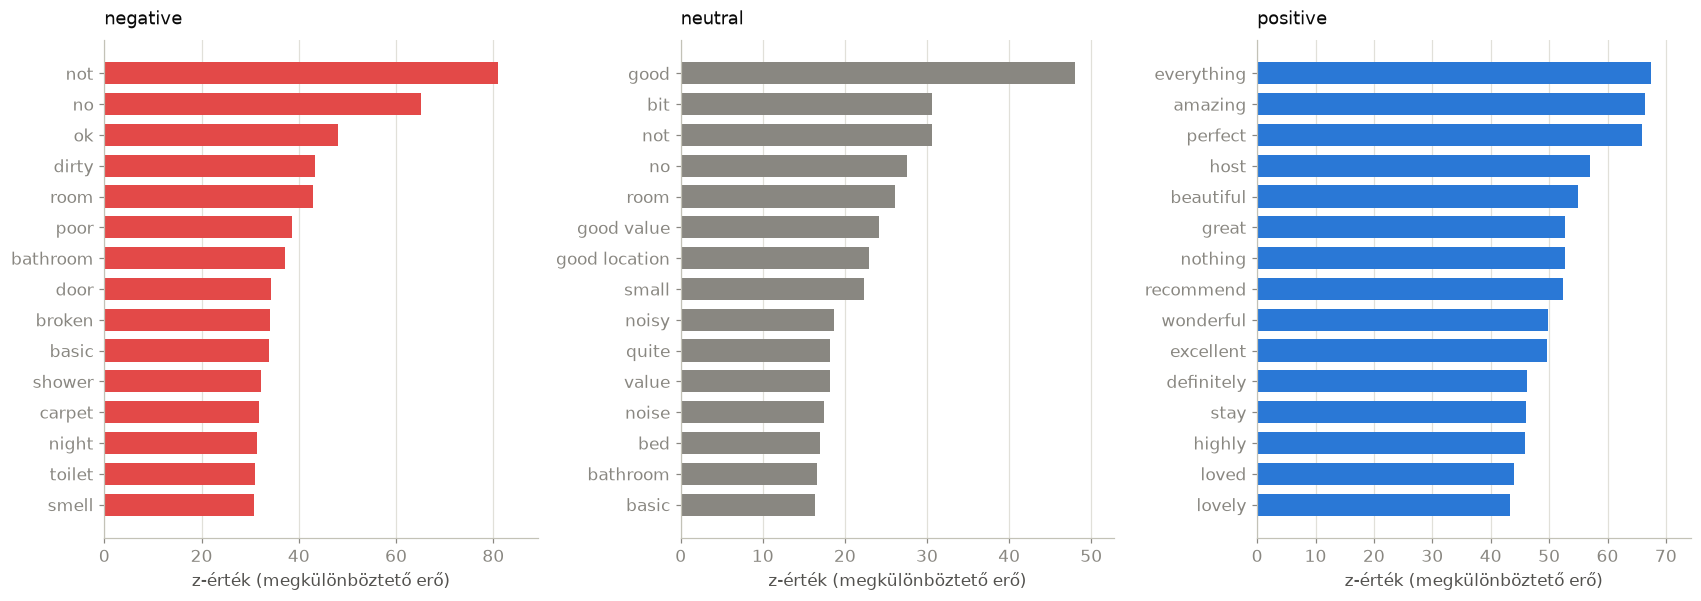

In [16]:
# Megkülönböztető kifejezések osztályonként.
# ngram_range=(1,2): szavak ÉS szópárok. A szópárok a lényegesek — a
# "not clean" csak bigramként létezik.
#
# FONTOS: a `text_clean` oszlopot használjuk, ahol a tagadószavak MEGMARADTAK
# (keep_negations=True). Ha kiestek volna, ez az egész elemzés értelmetlen lenne.
dist = ta.distinctive_terms(
    df["text_clean"], df["sentiment"],
    ngram_range=(1, 2), top_n=15, min_count=50,
)
ev.save_table(dist, "01_distinctive_terms")

ta.plot_distinctive_terms(dist, top_n=15, save_as="01_distinctive_terms")
plt.show()

11:44:59 | INFO    | src.text_analysis | Szókincs: 14435 kifejezés (2-3-gram), összesen 2739556 token
11:44:59 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_distinctive_multiword.csv
11:45:00 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_distinctive_multiword.png


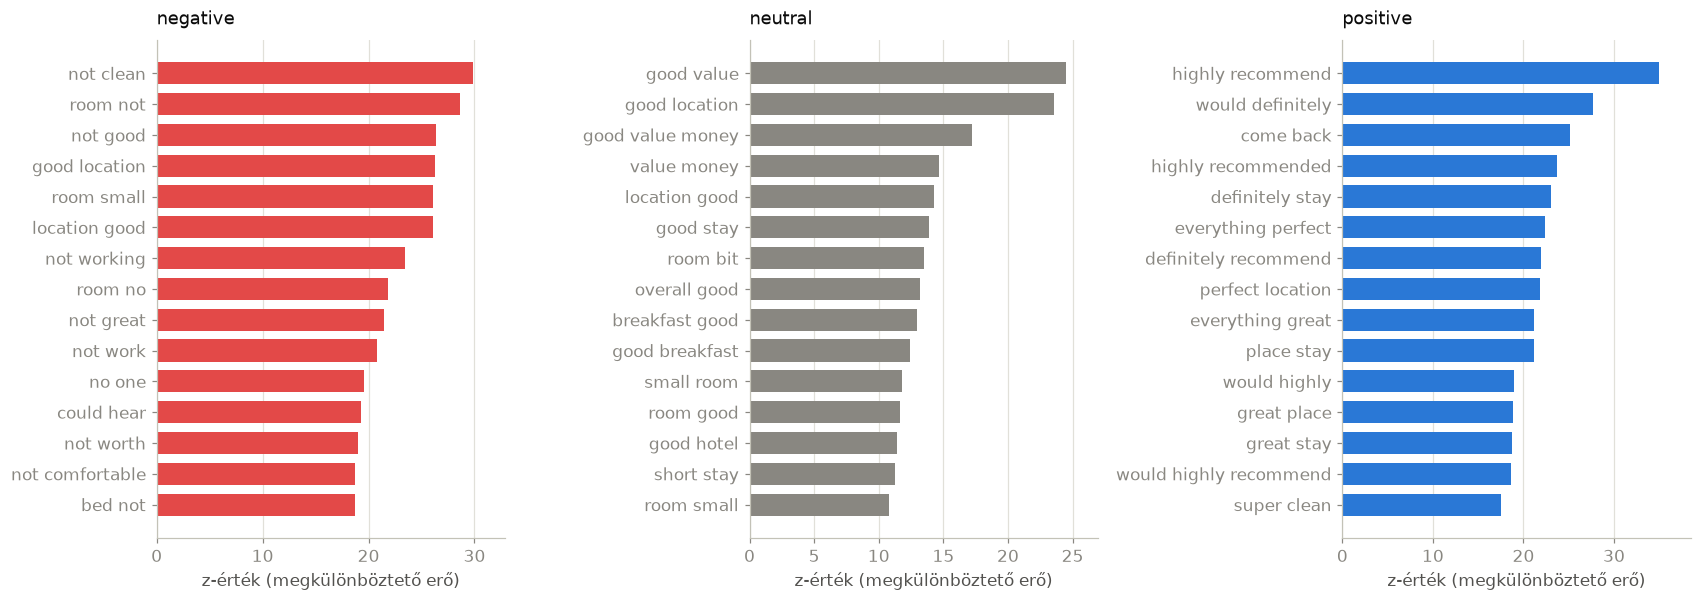


=== NEGATIVE — többszavas kifejezések ===
    kifejezés   z_érték  db_osztályban    arány
    not clean 29.894438            457 8.187488
     room not 28.592536            848 3.345316
     not good 26.335244            585 3.985309
good location 26.245319           2662 1.770161
   room small 26.098628            834 2.975194
location good 26.042761           1454 2.200165
  not working 23.407982            472 3.909519
      room no 21.839409            492 3.362342
    not great 21.440310            397 3.901123
     not work 20.807296            316 4.626221

=== NEUTRAL — többszavas kifejezések ===
       kifejezés   z_érték  db_osztályban    arány
      good value 24.504786           2386 1.863766
   good location 23.533193           3925 1.571599
good value money 17.252094           1265 1.822940
     value money 14.662577           2975 1.373542
   location good 14.268115           1760 1.503278
       good stay 13.887991            566 2.100539
        room bit 13.479684    

In [17]:
# === CSAK TÖBBSZAVAS KIFEJEZÉSEK ===
# Az előző cella (1,2) tartományt használt, ott az egyszavas kifejezések
# nyomják el a szópárokat, mert gyakoribbak. Itt az alsó határt 2-re emeljük,
# így KIZÁRÓLAG két- és háromszavas kifejezések versenyeznek egymással.
#
# Ez mutatja meg azt, amit az egyszavas reprezentáció elveszít:
# "not clean", "no hot water", "would not recommend" — olyan jelentések,
# amelyek egyetlen szóból nem rakhatók össze.

multi = ta.distinctive_terms(
    df["text_clean"], df["sentiment"],
    ngram_range=(2, 3),      # <- EZ a különbség: nincs unigram
    top_n=15,
    min_count=50,            # 200k soron ez ésszerű; kisebb mintán csökkentsd
)
ev.save_table(multi, "01_distinctive_multiword")

ta.plot_distinctive_terms(multi, top_n=15, save_as="01_distinctive_multiword")
plt.show()

# Táblázatos formában, a számokkal együtt
for cls in CFG.labels:
    sub = multi[multi["sentiment"] == cls].head(10)
    print(f"\n=== {cls.upper()} — többszavas kifejezések ===")
    print(sub[["kifejezés", "z_érték", "db_osztályban", "arány"]].to_string(index=False))

In [18]:
# Ugyanez táblázatban, hogy a számokat is lásd
for cls in CFG.labels:
    sub = dist[dist["sentiment"] == cls].head(10)
    print(f"\n=== {cls.upper()} ===")
    print(sub[["kifejezés", "z_érték", "db_osztályban", "arány"]]
          .to_string(index=False))
print("\n'arány' = hányszor gyakoribb ebben az osztályban, mint a többiben")


=== NEGATIVE ===
kifejezés   z_érték  db_osztályban    arány
      not 81.055996          15132 2.152476
       no 65.161795           8940 2.247461
       ok 47.984273           2076 3.928182
    dirty 43.286535           1098 7.070505
     room 42.989084          29248 1.313593
     poor 38.538315           1075 5.010227
 bathroom 37.108216           5449 1.775132
     door 34.214792           2704 2.163971
   broken 34.089864            782 5.544229
    basic 33.917125           1361 3.141973

=== NEUTRAL ===
    kifejezés   z_érték  db_osztályban    arány
         good 48.006375          26977 1.410089
          bit 30.653504           5758 1.634088
          not 30.641186          15625 1.332982
           no 27.564702           9283 1.403628
         room 26.145497          39930 1.160162
   good value 24.099275           2386 1.846558
good location 22.980163           3925 1.557089
        small 22.364078           5599 1.427218
        noisy 18.624252           1811 1.710962
 

### Tagadáselemzés — mikor kell összerakni a szavakat?

Ez a kérdés a dolgozat **RQ2** magja, és itt kapja meg a számszerű választ.

A TF-IDF alapesetben **zsák-a-szavak** modell: nem tudja, hogy a `not` a
`good` előtt áll-e vagy egy másik mondatban. Ha csak egyszavas jellemzőket
(unigramokat) használna, a `"not good"` pontosan ugyanúgy nézne ki, mint a
`"good"` — plusz egy `not`.

Az alábbi cellák megmérik, **mennyit számít ez valójában**:

1. mely tagadott szópárok a leggyakoribbak, és melyik osztályba esnek;
2. ugyanaz a szó önmagában vs. tagadva — mennyivel tolódik a negatív osztály felé;
3. mennyivel lesz megkülönböztetőbb a szókincs, ha szópárokat is megengedünk.

A 02-es notebook ablációs vizsgálata ugyanezt a kérdést **modellteljesítményben**
fogja megmérni. Ez itt a nyelvi oldal, az ott a mérnöki — a kettő együtt ad
teljes választ.

In [19]:
# 1) Tagadással kezdődő szópárok
neg_bi = ta.negation_bigrams(df["text_clean"], df["sentiment"],
                             top_n=25, min_count=50)
display(neg_bi)
ev.save_table(neg_bi, "01_negation_bigrams")

print("\nOlvasat: 'neg_lift' = hányszorosa az adott szópár negatív aránya")
print("az adathalmaz átlagának. 1,0 felett negatív irányba húz.")

,összes,negative,neutral,positive,neg_lift
bigram,,,,,
not clean,819,0.5580,0.2784,0.1636,4.2635
not work,759,0.4163,0.3057,0.2780,3.1811
no one,746,0.3995,0.2909,0.3097,3.0522
not good,1537,0.3806,0.3155,0.3038,2.9082
not working,1255,0.3761,0.3275,0.2964,2.8737
not great,1057,0.3756,0.3377,0.2867,2.8698
not bad,724,0.3660,0.3204,0.3135,2.7967
not comfortable,911,0.3600,0.3425,0.2975,2.7510
no breakfast,752,0.3085,0.3059,0.3856,2.3573


11:45:24 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_negation_bigrams.csv



Olvasat: 'neg_lift' = hányszorosa az adott szópár negatív aránya
az adathalmaz átlagának. 1,0 felett negatív irányba húz.


,db (önmagában),negatív arány (önmagában),db (tagadva),negatív arány (tagadva),különbség,lift (tagadva)
szó,,,,,,
clean,72172,0.1111,831,0.5475,0.4364,4.1836
friendly,44970,0.0989,309,0.3819,0.2830,2.9178
nice,46361,0.1364,315,0.3905,0.2541,2.9835
recommend,13383,0.0344,251,0.2869,0.2524,2.1918
comfortable,49683,0.1030,920,0.3533,0.2502,2.6992
hot water,1880,0.2069,338,0.4497,0.2428,3.4361
helpful,32380,0.0862,238,0.3067,0.2205,2.3436
great,70992,0.0914,1371,0.2830,0.1916,2.1624
quiet,16419,0.1012,39,0.2564,0.1552,1.9592


11:45:50 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_negation_effect.csv
11:45:50 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_negation_effect.png


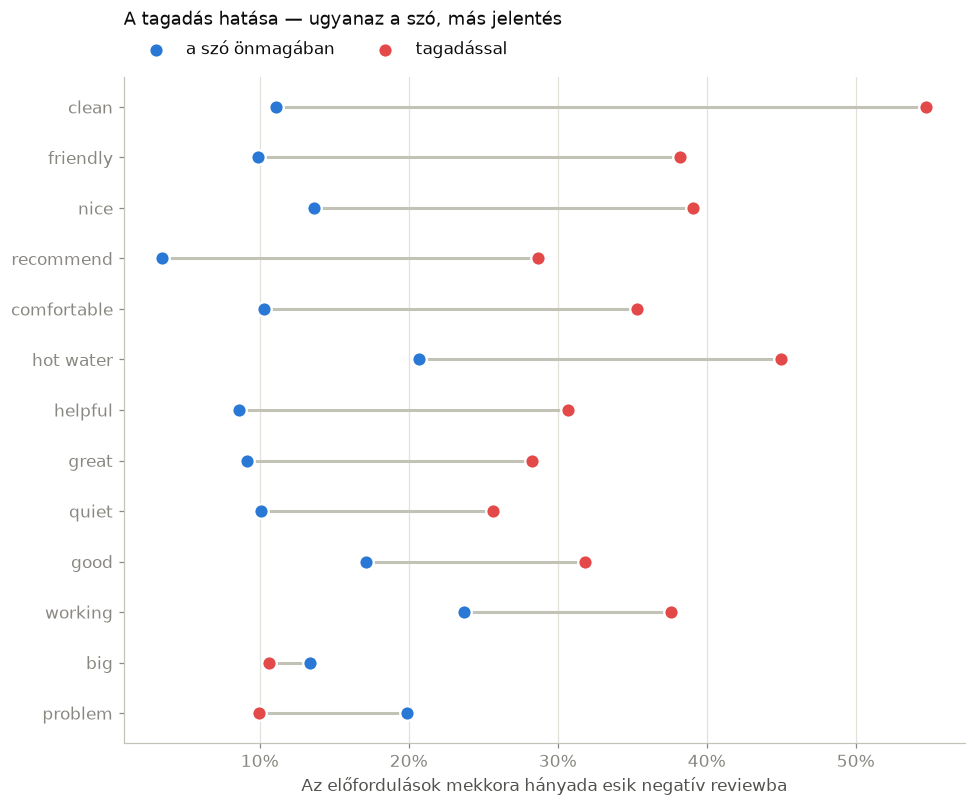

In [20]:
# 2) A KULCSKÍSÉRLET: ugyanaz a szó önmagában vs. tagadva
neg_effect = ta.compare_with_without_negation(df["text_clean"], df["sentiment"])
display(neg_effect)
ev.save_table(neg_effect, "01_negation_effect")

ta.plot_negation_effect(neg_effect, save_as="01_negation_effect")
plt.show()

> **Ez a táblázat az egyik legerősebb eredményed.** Ha a `"good"` előfordulásainak
> mondjuk 8%-a esik negatív reviewba, a `"not good"`-é viszont 60%, akkor
> bizonyítottad, hogy az unigram-reprezentáció elveszít valamit, ami
> **számszerűen jelentős** — nem csak elvben.
>
> Ezt írd be a naplóba konkrét számokkal. A 02-es notebook ablációjában ehhez
> fogod kötni a macro-F1 különbséget: "a tagadószavak eldobása X ponttal
> rontott, ami összhangban van azzal, hogy a tagadott alakok negatív aránya
> Y-szorosa a puszta alakokénak".

In [21]:
# 3) Mennyivel gazdagabb a szókincs magasabb n-gram szinten?
# (Ez pár percig fut, mert háromszor építi fel a szókincset.)
ngram_cmp = ta.ngram_level_comparison(df["text_clean"], df["sentiment"], min_count=50)
display(ngram_cmp)
ev.save_table(ngram_cmp, "01_ngram_levels")

print("\nA 'többszavas a top-50-ben' oszlop mutatja, hogy a legjellemzőbb")
print("kifejezések hányad része többszavas. Ha ez magas, a szópárok valódi")
print("információt hordoznak -> a (1,2) ngram_range indokolt a TF-IDF-ben.")

11:46:01 | INFO    | src.text_analysis | Szókincs: 4408 kifejezés (1-1-gram), összesen 5318061 token
11:46:13 | INFO    | src.text_analysis | Szókincs: 15619 kifejezés (1-2-gram), összesen 7647315 token
11:46:43 | INFO    | src.text_analysis | Szókincs: 18843 kifejezés (1-3-gram), összesen 8057617 token


,top-50 átlagos z,többszavas a top-50-ben,példa (negatív)
n-gram szint,,,
"unigram (1,1)",26.742,0.000,—
"uni+bigram (1,2)",27.587,0.173,"not clean, room not, not good"
"uni+bi+trigram (1,3)",27.686,0.180,"not clean, room not, not good"


11:46:43 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_ngram_levels.csv



A 'többszavas a top-50-ben' oszlop mutatja, hogy a legjellemzőbb
kifejezések hányad része többszavas. Ha ez magas, a szópárok valódi
információt hordoznak -> a (1,2) ngram_range indokolt a TF-IDF-ben.


## 7. Leíró statisztikák és kereszttáblák

Itt lépünk túl azon, hogy "hány sor van az adatban". A Booking.com metaadatai
(ország, szállástípus, vendégtípus, csillagbesorolás) lehetővé teszik, hogy a
sentimentet **ezek mentén** vizsgáld — ezt csinálná egy szállodalánc elemzője is.

### A központi mutató: a LIFT

Nem elég azt mondani, hogy „a hostelek 35%-a negatív". Tudni kell, hogy ez sok-e:

```
lift = a csoport negatív aránya / a teljes adathalmaz negatív aránya

lift = 1,0  →  pontosan átlagos
lift = 1,4  →  40%-kal gyakrabban negatív az átlagnál
lift = 0,7  →  30%-kal ritkábban
```

Így az eltérő méretű csoportok is összehasonlíthatók, és egyetlen szám megmondja,
hol van a probléma.

### Egy szó a színekről

Az ábrák **piros–szürke–kék** skálát használnak, nem piros–zöldet. A vörös-zöld
színtévesztés a férfiak kb. 8%-át érinti, és pont ezt a két színt mossa össze —
egy kinyomtatott szakdolgozatnál ez valós olvashatósági probléma. A piros–kék pár
színtévesztéssel is elkülöníthető marad.

In [22]:
# A csillagbesorolás 0 értéke NEM "nulla csillag", hanem "nincs besorolás".
# Ha nem kezeljük, önálló kategóriaként jelenne meg, és a rendezésben a
# legrosszabbnak látszana — miközben hiányzó adat.
df = ds.prepare_star_rating(df)

# A guest_country oszlop a Booking-kiadásban ÁLNEVESÍTETT (Fuxa, Xazas,
# Nukeye...). Adatvédelmi okból nem valódi országnevek. A csoportok közti
# eltérés így is mérhető, de NEM nevezhető meg, melyik ország melyik —
# ezért a kereszttáblákból kihagyjuk. Ha mégis használod, ezt a korlátot
# a dolgozatban külön jelezni kell.
if "guest_country" in df.columns:
    n_anon = df["guest_country"].nunique()
    print(f"guest_country: {n_anon} egyedi érték, álnevesítve — kihagyva az elemzésből.")
    print("Példák:", df["guest_country"].dropna().unique()[:6].tolist())

11:47:23 | INFO    | src.descriptives | Csillagbesorolás: 64997 sor (32.0%) 0 értékű volt -> 'n. a.' kategóriába került.


guest_country: 209 egyedi érték, álnevesítve — kihagyva az elemzésből.
Példák: ['Jof', 'Mejok', 'Zuc', 'Sajeb', 'Dawal', 'Gobuf']


In [23]:
# Áttekintő tábla — ez megy a dolgozat 4. és 9. fejezetébe
overview = ds.dataset_overview(df)
display(overview)
ev.save_table(overview, "01_dataset_overview")

,Érték
Mutató,
Reviewk száma,"203,328"
Egyedi szálláshelyek,"5,000"
Országok száma,120
Szállástípusok,24
Átlagos pontszám,8.87
Medián pontszám,9.00
Pontszám szórása,1.16
Átlagos reviewhossz (szó),49.2
Medián reviewhossz (szó),37


11:47:28 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_dataset_overview.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/01_dataset_overview.csv')

In [24]:
# Numerikus oszlopok profilja
prof = ds.numeric_profile(df)
display(prof)
ev.save_table(prof, "01_numeric_profile")

,count,mean,std,min,5%,25%,50%,75%,95%,max
score,203328.0,8.87,1.16,3.0,7.0,8.0,9.0,10.0,10.0,10.0
n_words,203328.0,49.21,43.67,1.0,9.0,21.0,37.0,63.0,130.0,733.0
n_chars,203328.0,278.88,237.37,10.0,55.0,126.0,214.0,355.0,716.0,3922.0
room_nights,203328.0,2.59,2.39,1.0,1.0,1.0,2.0,3.0,7.0,112.0
accommodation_score,203328.0,8.38,0.74,4.2,7.0,8.0,8.4,8.9,9.5,10.0
review_helpful_votes,203328.0,0.14,0.78,0.0,0.0,0.0,0.0,0.0,1.0,87.0


11:47:37 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_numeric_profile.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/01_numeric_profile.csv')

11:48:01 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_counts_accommodation_country.png


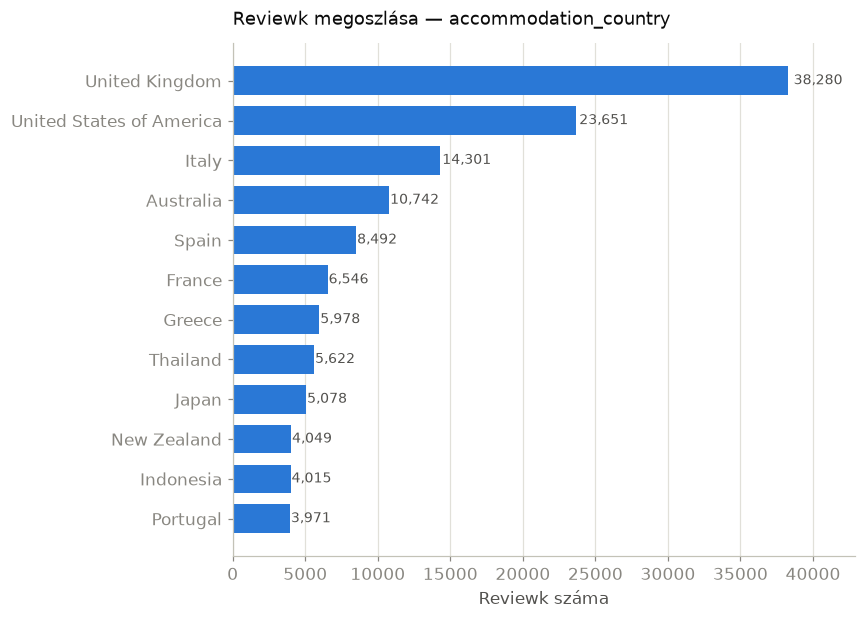

11:48:02 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_counts_accommodation_type.png


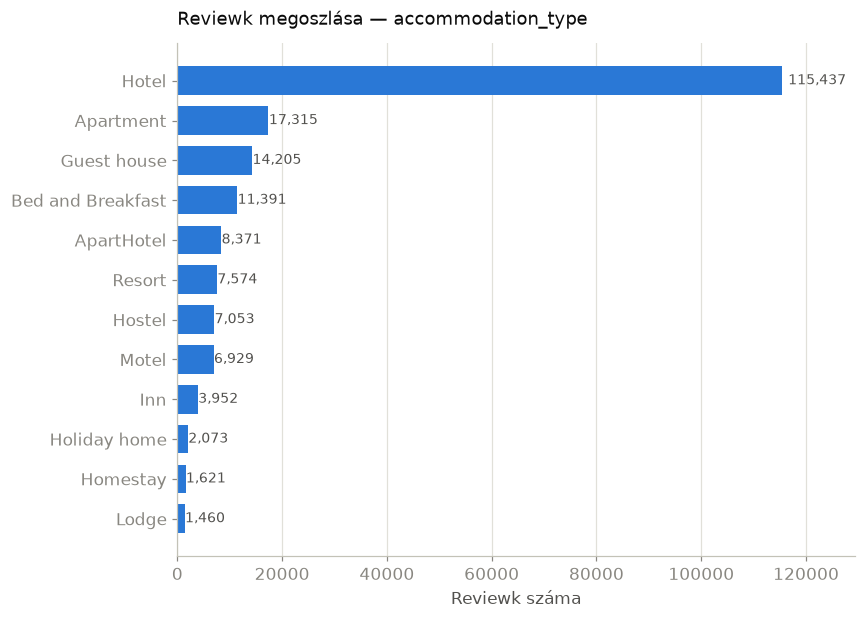

11:48:02 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_counts_guest_type.png


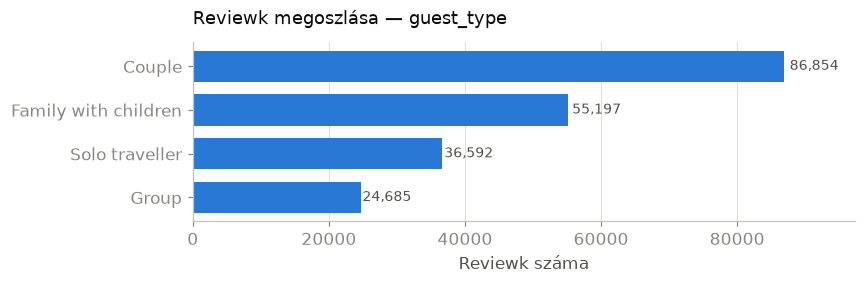

In [25]:
# Melyik kategóriából van a legtöbb review? (Ezt tudni kell, mielőtt
# bármilyen csoportos összehasonlítást értelmeznél.)
for col in ["accommodation_country", "accommodation_type", "guest_type"]:
    if col in df.columns:
        ds.plot_top_categories(df, col, top_n=12,
                               title=f"Reviewk megoszlása — {col}",
                               save_as=f"01_counts_{col}")
        plt.show()

In [26]:
# === A FŐ KERESZTTÁBLA-FUTTATÁS ===
# Minden elérhető dimenzióra: tábla + ábra, automatikusan mentve.
#
# min_count=200: ennél kevesebb reviewval rendelkező kategóriát eldobunk.
#   MIÉRT? Mert 12 reviewból számolt 50%-os negatív arány statisztikai zaj,
#   nem megállapítás. Ezt a küszöböt a dolgozatban meg kell említeni.
crosstabs = ds.run_all_crosstabs(
    df, min_count=200, top_n=12, save=True,
    dims={k: v for k, v in {
        "accommodation_country": "szálláshely országa",
        "accommodation_type": "szállástípus",
        "guest_type": "vendégtípus",
        "accommodation_star_rating": "csillagbesorolás",
    }.items() if k in df.columns},
)

print(f"\nElkészült {len(crosstabs)} kereszttábla.")

11:48:21 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_crosstab_accommodation_country.csv
11:48:21 | WARNING | matplotlib.font_manager | findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
11:48:22 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_crosstab_accommodation_country.png
11:48:22 | INFO    | src.descriptives | accommodation_country        12 kategória, neg_lift tartomány 0.49–1.48
11:48:22 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_crosstab_accommodation_type.csv
11:48:22 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_crosstab_accommodation_type.png
11:48:22 | INFO    | src.descriptives | accommodation_type           12 kategória, neg_li


Elkészült 4 kereszttábla.


In [27]:
# Nézzük meg részletesen a szállástípust — jellemzően itt a legnagyobb a szórás
if "accommodation_type" in crosstabs:
    display(crosstabs["accommodation_type"])
    print("\nOlvasat:")
    print("  neg_lift > 1  ->  ez a szállástípus PANASZHAJTÓ")
    print("  neg_lift < 1  ->  ELÉGEDETTSÉGHAJTÓ")

,n,részarány,negative,neutral,positive,neg_lift,pos_lift,átlagpont
accommodation_type,,,,,,,,
Motel,6929,0.0341,0.1993,0.2589,0.5418,1.5229,0.8402,8.5780
Resort,7574,0.0373,0.1583,0.2147,0.6270,1.2096,0.9724,8.7873
Hotel,115437,0.5677,0.1499,0.2467,0.6034,1.1453,0.9359,8.7553
Hostel,7053,0.0347,0.1433,0.2172,0.6394,1.0953,0.9917,8.8618
Lodge,1460,0.0072,0.1301,0.2130,0.6568,0.9943,1.0187,8.9171
ApartHotel,8371,0.0412,0.1186,0.2236,0.6577,0.9064,1.0201,8.9139
Inn,3952,0.0194,0.1172,0.2411,0.6417,0.8952,0.9952,8.8891
Guest house,14205,0.0699,0.0848,0.1833,0.7319,0.6476,1.1351,9.1159
Apartment,17315,0.0852,0.0774,0.1698,0.7528,0.5918,1.1675,9.1670



Olvasat:
  neg_lift > 1  ->  ez a szállástípus PANASZHAJTÓ
  neg_lift < 1  ->  ELÉGEDETTSÉGHAJTÓ


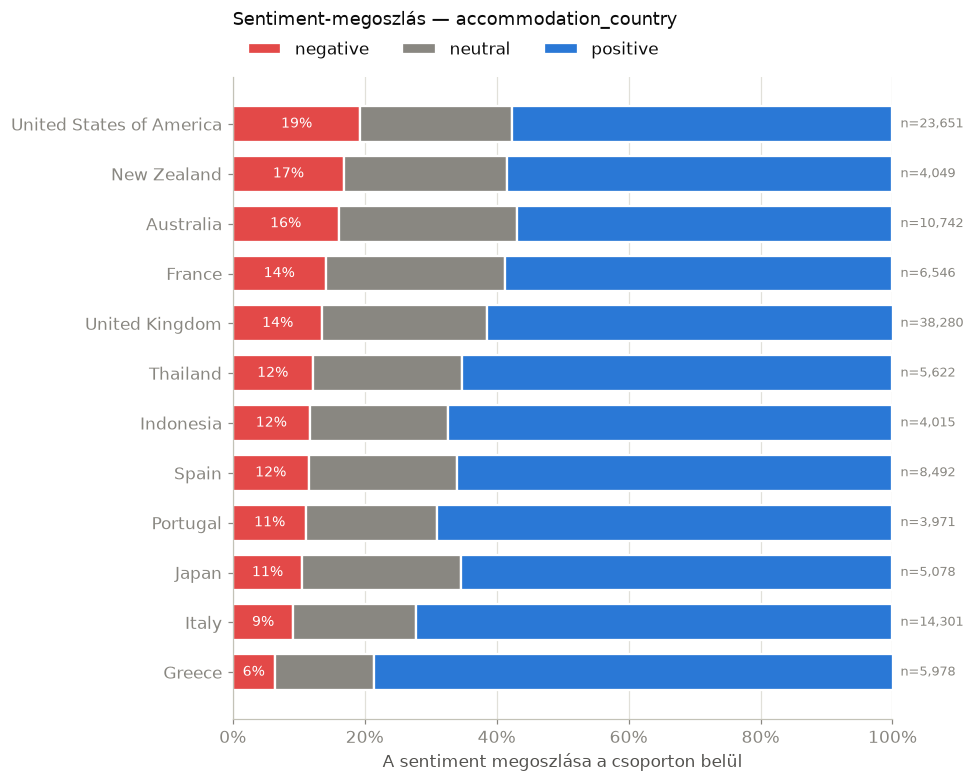

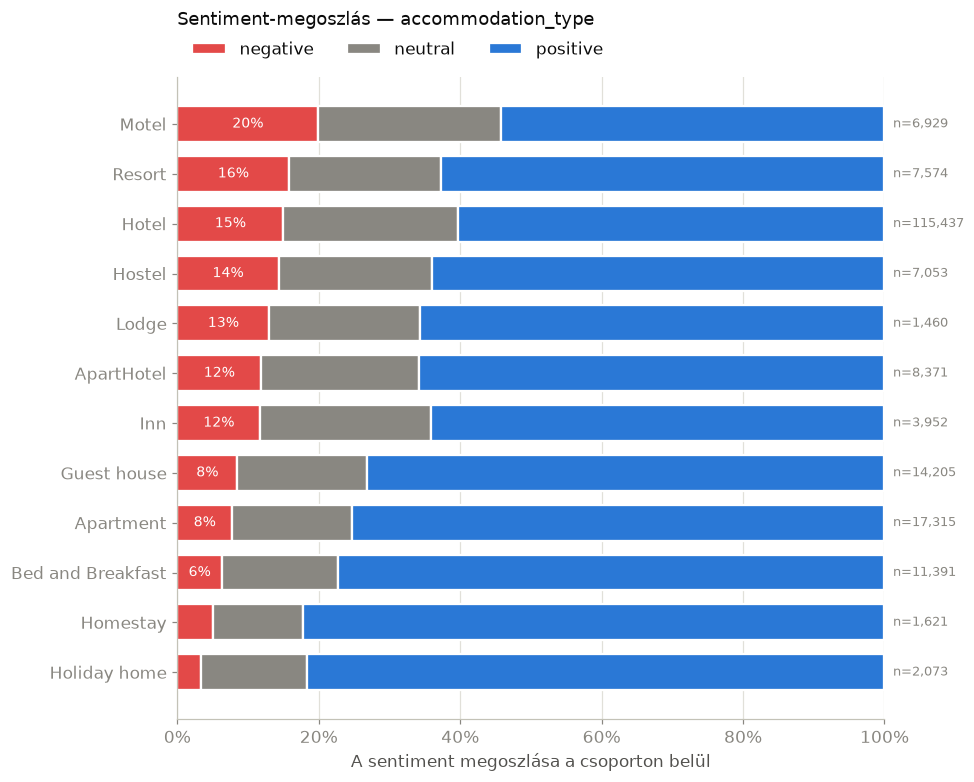

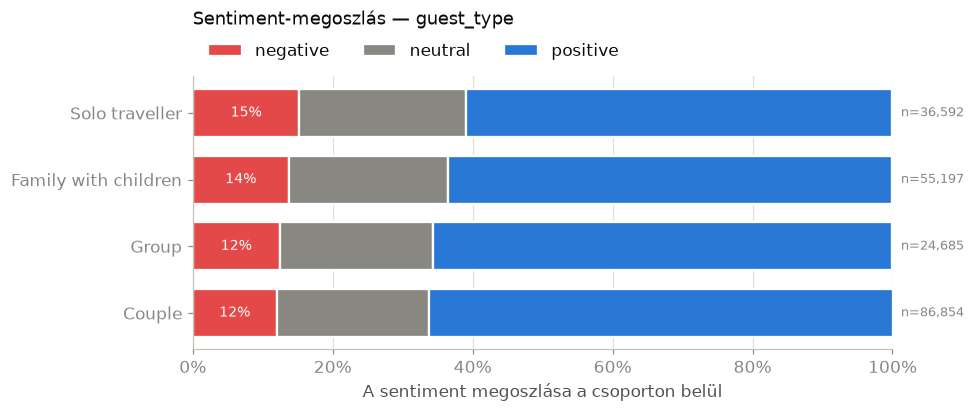

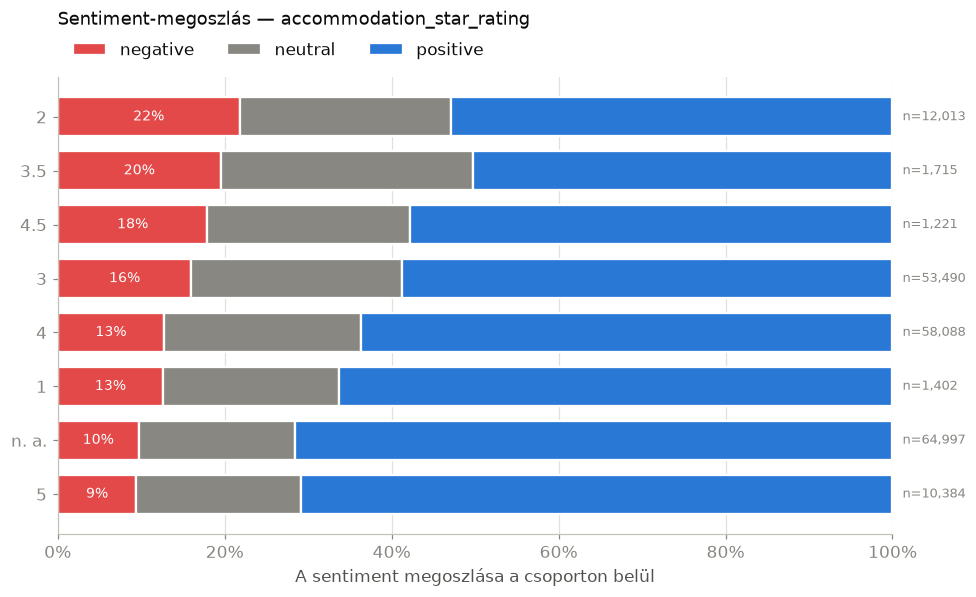

In [28]:
# Az ábrák már elmentődtek; itt újra megjelenítjük őket a notebookban
for col, tab in crosstabs.items():
    ds.plot_sentiment_by(tab, f"Sentiment-megoszlás — {col}")
    plt.show()

### Két dimenzió együtt — hőtérkép

Az egydimenziós táblák elrejthetnek egy összefüggést. Például lehet, hogy a
hostelek azért tűnnek rosszabbnak, mert jellemzően alacsonyabb csillagbesorolásúak
— nem azért, mert hostelek. A kereszttábla ezt szétválasztja.

A hőtérkép **divergáló** skálát használ: kék = az átlagnál **kevesebb** negatív,
piros = **több**. Azért divergálót, mert a kérdés nem „mennyi?", hanem „az
átlaghoz képest jobb vagy rosszabb?" — ennek van értelmes közepe (lift = 1,0).

accommodation_star_rating,2,3,3.5,4,5,n. a.
accommodation_type,,,,,,
ApartHotel,1.247,1.051,1.616,1.130,0.884,0.576
Apartment,0.445,0.762,NaN,0.615,0.335,0.585
Bed and Breakfast,NaN,0.912,NaN,0.301,0.186,0.466
Guest house,1.332,0.430,NaN,0.339,0.047,0.682
Hostel,0.672,0.875,NaN,NaN,0.289,1.164
Hotel,1.728,1.271,1.853,1.011,0.709,1.041
Motel,2.319,1.830,1.350,1.066,NaN,0.883
Resort,NaN,1.182,NaN,1.321,0.965,1.054


11:49:04 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_heatmap_type_x_stars.csv
11:49:05 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_heatmap_type_x_stars.png


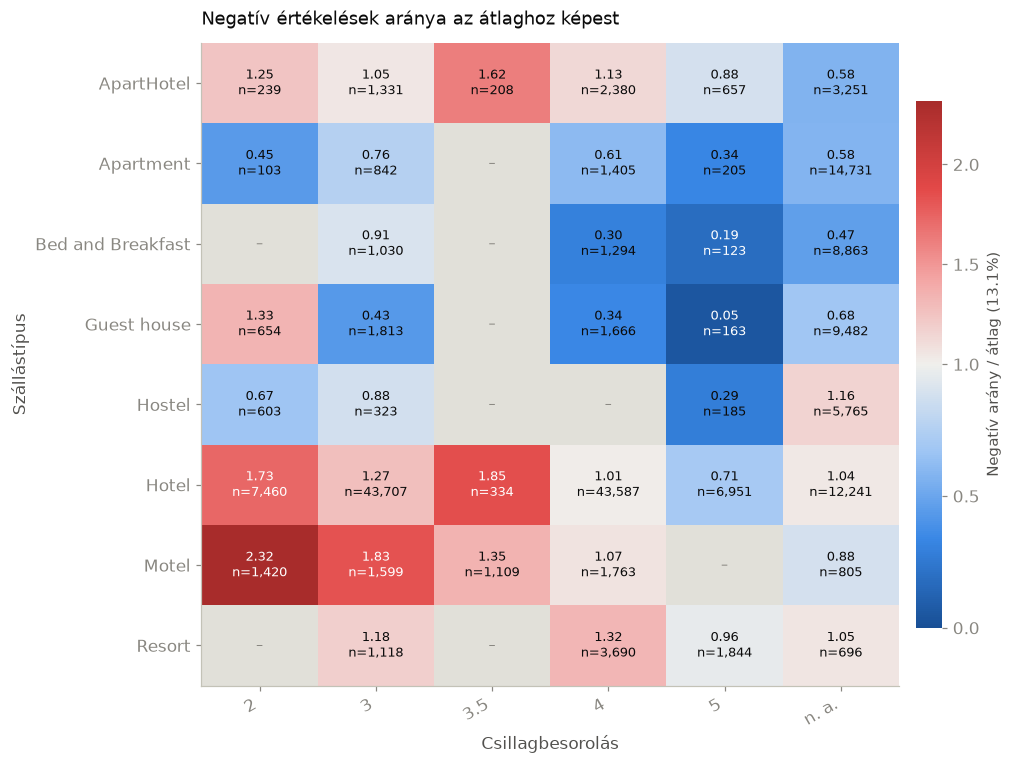

A szürke cellák: kevesebb mint 100 review — nem értelmezhető.


In [29]:
def heatmap(rows, cols, xlabel, ylabel, fname, min_count=100, top_rows=8, top_cols=6):
    """Hőtérkép egy sorban, hibatűrően.

    Ha minden cella kimaszkolódik (túl kevés review), nem áll meg a notebook,
    hanem kiírja, mit állíts át. Kis mintán ez elő szokott fordulni."""
    if not {rows, cols} <= set(df.columns):
        print(f"Kihagyva — nincs meg mindkét oszlop: {rows}, {cols}")
        return
    try:
        lift, counts, base = ds.negativity_heatmap(
            df, rows=rows, cols=cols,
            min_count=min_count, top_rows=top_rows, top_cols=top_cols,
        )
    except ValueError as e:
        print(f"Kihagyva: {e}")
        return
    display(lift)
    ev.save_table(lift, fname)
    ds.plot_negativity_heatmap(
        lift, counts, base,
        title="Negatív értékelések aránya az átlaghoz képest",
        xlabel=xlabel, ylabel=ylabel, save_as=fname,
    )
    plt.show()
    print(f"A szürke cellák: kevesebb mint {min_count} review — nem értelmezhető.")


# Szállástípus × csillagbesorolás
heatmap("accommodation_type", "accommodation_star_rating",
        xlabel="Csillagbesorolás", ylabel="Szállástípus",
        fname="01_heatmap_type_x_stars")

accommodation_type,ApartHotel,Apartment,Bed and Breakfast,Guest house,Hotel,Resort
accommodation_country,,,,,,
Australia,1.355,1.027,0.395,NaN,1.292,1.971
France,1.658,0.977,0.070,0.068,1.119,NaN
Greece,0.376,0.353,NaN,0.072,0.671,0.659
Italy,0.227,0.255,0.349,0.635,0.907,NaN
Japan,0.603,0.866,NaN,0.283,0.797,NaN
New Zealand,NaN,0.483,0.070,NaN,2.111,0.975
Spain,0.766,0.603,0.320,0.984,0.933,NaN
Thailand,NaN,NaN,NaN,1.065,0.836,1.126
United Kingdom,0.556,0.418,0.641,0.580,1.339,NaN


11:49:11 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_heatmap_country_x_type.csv
11:49:12 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_heatmap_country_x_type.png


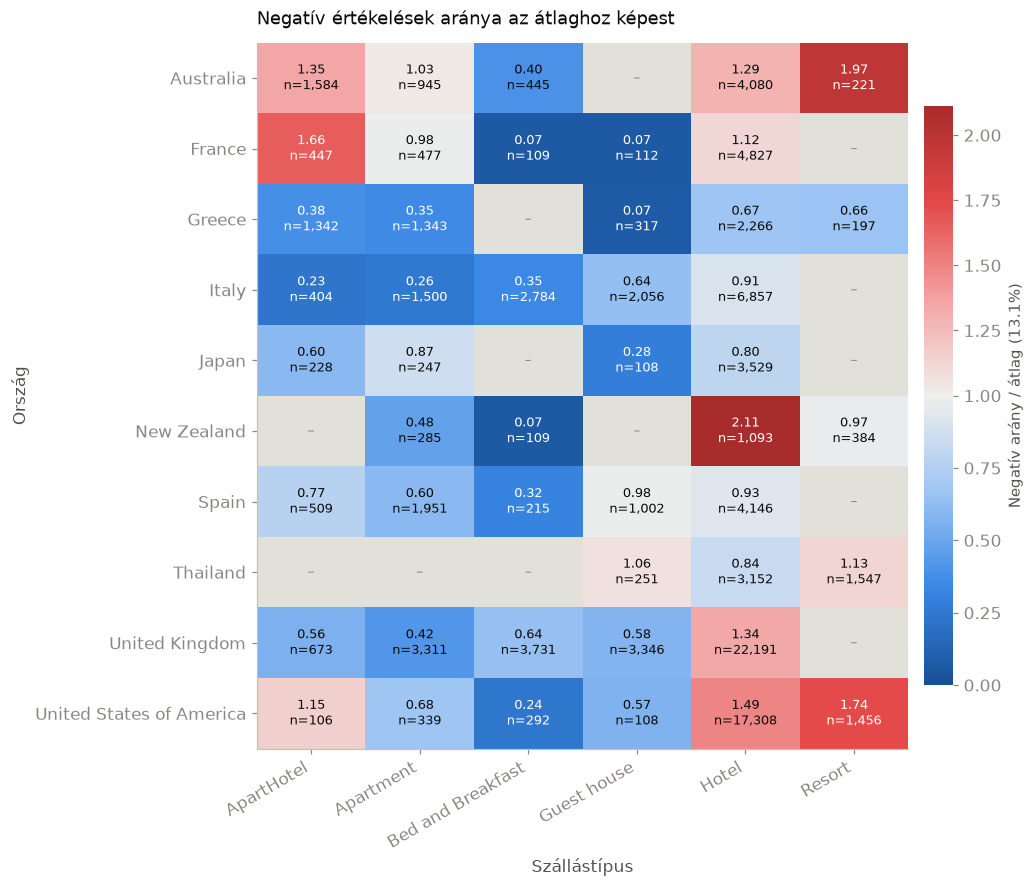

A szürke cellák: kevesebb mint 100 review — nem értelmezhető.


In [30]:
# Ország × szállástípus
heatmap("accommodation_country", "accommodation_type",
        xlabel="Szállástípus", ylabel="Ország",
        fname="01_heatmap_country_x_type", top_rows=10)

> **Írd le a naplóba, amit LÁTSZ** (`docs/naplo.md`):
> - Melyik szállástípus/ország a leginkább panaszhajtó, és mennyivel?
> - Eltűnik-e a hatás, ha a csillagbesorolást is figyelembe veszed? (Ha igen,
>   akkor a csillagbesorolás volt az igazi magyarázó változó — ez fontos
>   megkülönböztetés, és jól mutatja, miért kell kereszttábla.)
> - Van-e olyan vendégtípus, amelyik szisztematikusan szigorúbban értékel?
>
> **Figyelmeztetés a megfogalmazásra:** ezek **asszociációk**, nem oksági
> viszonyok. Ne azt írd, hogy „a hostel rosszabb élményt ad", hanem hogy
> „a hostel kategóriában az átlagnál gyakoribb a negatív értékelés". A dolgozatod
> 7. fejezete már helyesen rögzíti ezt a különbséget.

## 8. Aspektus-előzetes

In [31]:
# Mondatra bontás + kulcsszavas aspektusdetektálás.
# Ez a BASELINE, amihez a későbbi transformer-alapú ABSA-t hasonlítod (RQ4).
# Lassú művelet, ezért mintán futtatjuk.
sample = df.sample(min(30_000, len(df)), random_state=CFG.random_seed)

sent_df = asp.explode_to_sentences(sample, text_col="text")
sent_df = asp.add_aspect_columns(sent_df, text_col="sentence")

print(f"{len(sample):,} review -> {len(sent_df):,} mondat")
print(f"Átlagosan {sent_df['n_aspects'].mean():.2f} aspektus / mondat")
print(f"A mondatok {(sent_df['n_aspects'] == 0).mean():.1%}-ában nem talált aspektust.")
print("\n=> Ezek az IMPLICIT aspektusok ('we could not sleep' = zaj, kulcsszó")
print("   nélkül). A transformer ezek egy részét meg fogja találni — ez lesz")
print("   az egyik fő érved amellett, miért kell transformer-alapú ABSA.")

30,000 review -> 126,975 mondat
Átlagosan 1.06 aspektus / mondat
A mondatok 32.4%-ában nem talált aspektust.

=> Ezek az IMPLICIT aspektusok ('we could not sleep' = zaj, kulcsszó
   nélkül). A transformer ezek egy részét meg fogja találni — ez lesz
   az egyik fő érved amellett, miért kell transformer-alapú ABSA.


,említések,említési_arány,negative,neutral,positive,neg_lift,pos_lift
aspektus,,,,,,,
bathroom,6896,0.0543,0.2369,0.2794,0.4836,1.6245,0.7697
wifi,1073,0.0085,0.2116,0.2526,0.5359,1.4505,0.8529
value_for_money,6570,0.0517,0.2105,0.2766,0.5129,1.4432,0.8164
room,28699,0.2260,0.1825,0.2549,0.5626,1.2513,0.8954
noise,4609,0.0363,0.1792,0.2684,0.5524,1.2287,0.8792
parking,2462,0.0194,0.1669,0.2522,0.5808,1.1445,0.9244
facilities,9193,0.0724,0.1655,0.2558,0.5787,1.1344,0.9211
pool,3325,0.0262,0.1507,0.2400,0.6093,1.0331,0.9698
location,25481,0.2007,0.1375,0.2416,0.6209,0.9425,0.9883


11:49:33 | INFO    | src.evaluation | Táblázat elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\tables\01_aspect_sentiment_distribution.csv
11:49:33 | INFO    | src.evaluation | Ábra elmentve: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\figures\01_aspect_sentiment_stacked.png


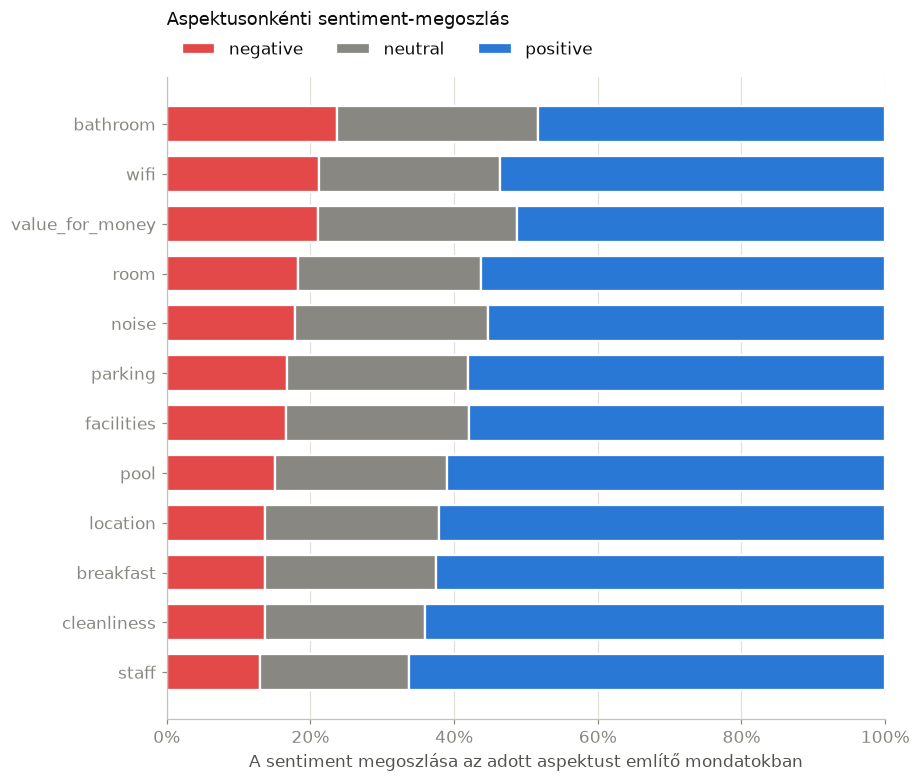

In [32]:
# RQ3 ELSŐ VÁLASZA: mely aspektusok kötődnek a negatív sentimenthez?
aspect_table = asp.aspect_sentiment_table(sent_df, min_count=100)
display(aspect_table)
ev.save_table(aspect_table, "01_aspect_sentiment_distribution")

asp.plot_aspect_sentiment(aspect_table, save_as="01_aspect_sentiment_stacked")
plt.show()

In [33]:
# Konkrét példák: hogyan néz ki a "textuális bizonyíték" kiemelése?
neg_sent = sent_df[(sent_df["sentiment"].astype(str) == "negative") &
                   (sent_df["n_aspects"] > 0)].head(8)

for _, r in neg_sent.iterrows():
    print(f"MONDAT: {r['sentence'][:150]}")
    for a in r["aspects"]:
        spans = asp.extract_evidence(r["sentence"], a)
        if spans:
            flag = "   [TAGADÁS!]" if asp.has_negation(spans[0]) else ""
            print(f'   • {a:16s} -> "{spans[0]}"{flag}')
    print()

MONDAT: Close by the main square, lovely and clean , amenities close by , great bathroom , staff online were great about a late check out and storing our case
   • staff            -> ", great bathroom , staff online were great about"
   • cleanliness      -> "main square, lovely and clean , amenities close by"
   • facilities       -> "lovely and clean , amenities close by , great"
   • bathroom         -> "close by , great bathroom , staff online were"

MONDAT: Pillows were awful and very lumpy , smoke alarm had no batteries and in a draw, picture for the room still in the cupboard.
   • room             -> "Pillows were awful and very"

MONDAT: Wi-Fi wouldn’t work for 2 days .
   • wifi             -> "Wi-Fi wouldn’t work for 2"

MONDAT: I did like the room but it was nothing like the pictures it was very plain .
   • room             -> "I did like the room but it was nothing"   [TAGADÁS!]

MONDAT: fine for one night at a low cost.
   • value_for_money  -> "night at a low cost."

M

> **Gyűjtsd a naplóba, hol bukik el a kulcsszavas módszer.** Keress példákat:
> tagadás („the room was **not** clean"), irónia, implicit aspektus, több
> aspektus egy mondatban ellentétes sentimenttel. Ez a lista lesz az RQ4
> indoklása — és egy önálló, értékes alfejezet.
>
> **Módszertani korlát, amit le kell írni:** itt a *review-szintű* sentimentet
> vetítjük a mondatokra, ami közelítés. Egy pozitív összpontszámú review is
> tartalmazhat negatív mondatot. A pontos mondat-szintű címkékhez kell a HRAST
> adathalmaz (4. fázis).

## 9. Felosztás és mentés

In [34]:
train_df, val_df, test_df = pp.train_val_test_split(df)

# Ellenőrzés: megmaradt az osztályarány mindhárom halmazban?
check = pd.DataFrame({
    "train": train_df["sentiment"].value_counts(normalize=True),
    "val":   val_df["sentiment"].value_counts(normalize=True),
    "test":  test_df["sentiment"].value_counts(normalize=True),
}).reindex(list(CFG.labels)).round(4)
display(check)
print("A három oszlopnak szinte azonosnak kell lennie -> a rétegzés működik.")

11:50:48 | INFO    | src.preprocessing | Felosztás — train: 121996 | val: 40666 | test: 40666


,train,val,test
sentiment,,,
negative,0.1309,0.1309,0.1309
neutral,0.2243,0.2243,0.2243
positive,0.6448,0.6448,0.6448


A három oszlopnak szinte azonosnak kell lennie -> a rétegzés működik.


In [35]:
# Mentés. A 02-es és 03-as notebook INNEN tölt be, így mindhárom modell
# PONTOSAN ugyanazon a felosztáson dolgozik — enélkül az RQ1 összehasonlítás
# értelmetlen lenne.
keep = ["review_id", "text", "text_clean", "text_bert", "score", "sentiment", "dataset"]
# A metaadatokat is visszük, hogy a hibaelemzésnél csoportosítani lehessen
# (pl. "melyik szállástípusnál hibázik legtöbbet a modell?")
keep += [c for c in ["accommodation_type", "accommodation_country",
                     "accommodation_star_rating", "guest_type"] if c in df.columns]

dl.save_splits({
    "train": train_df[keep],
    "val":   val_df[keep],
    "test":  test_df[keep],
})

# A konfigurációt is mentsük az adat mellé — így minden későbbi eredményhez
# tudni fogod, pontosan milyen beállításokkal készült ez a felosztás.
CFG.to_json(PATHS.processed / "config_snapshot.json")
print("\nKonfiguráció elmentve: config_snapshot.json")

11:50:56 | INFO    | src.data_loading | train  -> booking_train.parquet          (121996 sor)
11:50:56 | INFO    | src.data_loading | val    -> booking_val.parquet            (40666 sor)
11:50:56 | INFO    | src.data_loading | test   -> booking_test.parquet           (40666 sor)



Konfiguráció elmentve: config_snapshot.json


---

## Összefoglaló — mi készült el

### Ábrák (`results/figures/`)

| Fájl | Dolgozat-fejezet |
|---|---|
| `01_eda_overview.png` | 9. EDA — pontszám, osztályok, hosszak |
| `01_top_words_by_sentiment.png` | 9. EDA — mi hajtja a sentimentet |
| `01_counts_*.png` | 9. EDA — a minta összetétele |
| `01_crosstab_*.png` | **9. EDA — a leíró elemzés fő ábrái** |
| `01_heatmap_*.png` | 9. EDA — két dimenzió együtt |
| `01_aspect_sentiment_stacked.png` | 7. ABSA / RQ3 |

### Táblázatok (`results/tables/`)

| Fájl | Dolgozat-fejezet |
|---|---|
| `01_dataset_overview.csv` | 4. Data Sources |
| `01_label_threshold_sensitivity.csv` | **6.1 — a küszöbválasztás indoklása** |
| `01_numeric_profile.csv` | 9. EDA |
| `01_crosstab_*.csv` | 9. EDA |
| `01_heatmap_*.csv` | 9. EDA |
| `01_aspect_sentiment_distribution.csv` | **RQ3 első válasza** |

### Adat (`data/processed/`)

`booking_train.parquet`, `booking_val.parquet`, `booking_test.parquet` —
ezekből dolgozik a 02-es és a 03-as notebook.

---

## MOST írd meg a naplót

Nyisd meg a `docs/naplo.md`-t, és válaszolj:

1. **Miért a `val.csv`?** (részhalmaz, számításigény, reprezentativitás)
2. **Mi a licenc, és hogyan hivatkozod?** (CC BY-SA 4.0)
3. **Miért 6/8 a küszöb?** — az érzékenységi táblázattal alátámasztva
4. **Mit dobott ki a szűrés?** — a szűrési napló konkrét számaival
5. **Mi a feltűnő az eloszlásokban?** (kiegyensúlyozatlanság, hosszkülönbség)
6. **Mit mutatnak a kereszttáblák?** — melyik csoport panaszhajtó, és eltűnik-e
   a hatás, ha egy másik dimenziót is bevonsz
7. **Hol bukik el a kulcsszavas aspektusdetektálás?**

> Ez a hét pont a dolgozat 4., 6.1., 7. és 9. fejezetének a nyersanyaga.
> Sokkal könnyebb most leírni, mint három hónap múlva visszaemlékezni rá.

**Commit:**
```
git add .
git commit -m "01-es notebook lefutott: EDA, kereszttablak, split elmentve"
```

**Következő:** `02_classical_baseline.ipynb` — TF-IDF + Naive Bayes / LogReg / SVM.